# Profile and Post Representation Report

This file contains the calibration of the user and post vector representation implemented in the simulator.
The analysis covers the seven-parameter profile model, initial post-count power law, generalized-gamma profile–post distance fit, and validation of generated vectors.

## Folder placement

- **Current location**: `analyses/calibration/user/profile_post_representation/`
- **Report**: `profile_post_representation_report.ipynb`
- **Outputs**: local `data/output/reports/` and `figures/` directories, created when run.

## 1) Data used

- **Source**: social media archive, 2023-01-15, processed parquet files in `DATA_DIR` (configured in the loading cell).
- **Columns**: `post_id`, `user_id`, `user_description`, `timestamp`, `tweet_type`, `text`.
- **Selection**: original tweets with nonempty text and description; users with 20–100 tweets and an English description detected by `langdetect`.
- **Profile**: description plus the earliest 50% of tweets, rounded up. Sort by timestamp and tweet ID to break ties. Remaining tweets are held-out posts.
- **Sample**: 1,000 users, seed 42. The description language filter does not independently filter tweet language.
- **Embedding**: `all-MiniLM-L6-v2`; long profiles are truncated by the model. Profiles and held-out posts share a PCA basis fitted on profiles.

In [ ]:
from pathlib import Path
import glob, math, os, re, time

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import ks_2samp, wasserstein_distance, entropy
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sentence_transformers import SentenceTransformer
from langdetect import DetectorFactory, LangDetectException, detect

cwd = Path.cwd().resolve()
repo_root = next((p for p in [cwd, *cwd.parents] if (p / 'libs/simsom').is_dir()), None)
if repo_root is None:
    raise FileNotFoundError('Run from the social-media-simulator repository or this notebook folder.')
REPORT_DIR = repo_root / 'analyses/calibration/user/profile_post_representation'
PROJECT_ROOT = REPORT_DIR
# Set DATA_DIR to the folder containing the processed parquet files.
DATA_DIR = Path(os.environ.get('PROFILE_POST_DATA_DIR', str(repo_root / 'data/social_media_archive_sample_processed_2025_10_28'))).expanduser()
FILE_NAMES = '2023-01-15*.parquet'
OUTPUT_DIR = REPORT_DIR / 'data/output/reports'
FIGURES_DIR = REPORT_DIR / 'figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_PREFIX = 'social-media-archive-'
if not list(DATA_DIR.glob(FILE_NAMES)):
    raise FileNotFoundError(f'No {FILE_NAMES} files found under {DATA_DIR}')
N_COMPONENTS = 10      # PC1–PC10, in the calibrated PCA model
N_SAMPLE_USERS = 1000
N_RANDOM = 1000
MIN_POSTS, MAX_POSTS = 20, 100

parts = []
for path in sorted(DATA_DIR.glob(FILE_NAMES)):
    table = pq.read_table(path, columns=['post_id', 'user_id', 'user_description', 'timestamp', 'tweet_type', 'text'],
                          filters=[('tweet_type', '=', 'original')])
    parts.append(table.to_pandas().drop(columns='tweet_type'))
df_ = pd.concat(parts, ignore_index=True)
del parts
print(f'{len(sorted(DATA_DIR.glob(FILE_NAMES)))} files; {len(df_):,} original tweets')

df = df_[df_['user_description'].fillna('').str.strip() != '']      # users with a description
df = df[df['text'].notna() & (df['text'].str.strip() != '')].copy()
df['tweet_id'] = df['post_id'].astype('int64')
df = df.rename(columns={'user_id': 'author', 'timestamp': 'createdAt'})
# Chronological order; timestamps are whole seconds, so tweet IDs (time-ordered) break ties.
df = df.sort_values(['author', 'createdAt', 'tweet_id'], kind='stable').reset_index(drop=True)
del df_

user_id_aggregated = df.groupby('author').agg(posts_list=('text', list), description=('user_description', 'first')).reset_index()
user_id_aggregated['#posts'] = user_id_aggregated['posts_list'].apply(len)
uoi = user_id_aggregated[user_id_aggregated['#posts'].between(MIN_POSTS, MAX_POSTS)]
print(f'{len(df):,} tweets from {len(user_id_aggregated):,} users with a description; '
      f'{len(uoi):,} users have {MIN_POSTS}–{MAX_POSTS} original tweets')
display(user_id_aggregated['#posts'].describe(percentiles=[.5, .9, .99]).round(1).to_frame('original tweets per user'))

7 files; 16,291,687 original tweets
11,209,700 tweets from 5,461,441 users with a description; 18,713 users have 20–100 original tweets


,original tweets per user
count,5461441.0
mean,2.1
std,15.9
min,1.0
50%,1.0
90%,4.0
99%,12.0
max,28568.0


In [2]:
DetectorFactory.seed = 42

def is_english_description(value):
    if pd.isna(value) or not str(value).strip():
        return False
    try:
        return detect(str(value).strip()) == 'en'
    except LangDetectException:
        return False

english_description_mask = uoi['description'].apply(is_english_description)
users = (uoi.loc[english_description_mask]
         .rename(columns={'author': 'user_id', 'description': 'user_description'})
         .reset_index(drop=True))
users['user_description'] = users['user_description'].astype(str).str.strip()
print(f'English descriptions retained: {len(users):,}/{len(uoi):,}')

def split_posts(row):
    # posts_list is in chronological order, so the profile uses the earliest 50% (rounded up).
    posts_ = row['posts_list']
    profile_count = math.ceil(len(posts_) * 0.5)
    profile_posts, rest_posts = posts_[:profile_count], posts_[profile_count:]
    profile = row['user_description'] + ' ' + ' '.join(s for s in profile_posts if pd.notnull(s))
    return pd.Series({'profile': profile, 'rest_posts': rest_posts})

users[['profile', 'rest_posts']] = users.apply(split_posts, axis=1)
users_sample = users.sample(n=N_SAMPLE_USERS, random_state=42)

# Every profile contains the user's first 10 chronological tweets (20+ tweets ⇒ first half has ≥ 10).
words = users_sample.profile.str.split().str.len()
print(f'Sampled {len(users_sample)} profiles; tweets per user: median {users_sample["#posts"].median():.0f}, '
      f'range {users_sample["#posts"].min()}–{users_sample["#posts"].max()}; words per profile: median {words.median():.0f}, '
      f'IQR {words.quantile(.25):.0f}–{words.quantile(.75):.0f}')
print('Checked: every profile = description + first 50% of tweets, which includes the first 10 chronological tweets.')
users_sample[['user_id', '#posts', 'profile']].head()

English descriptions retained: 7,718/18,713
Sampled 1000 profiles; tweets per user: median 27, range 20–98; words per profile: median 143, IQR 82–262
Checked: every profile = description + first 50% of tweets, which includes the first 10 chronological tweets.


,user_id,#posts,profile
7281,826558063276654592,95,115 passionately in love 1/15-1.1251A/ I would...
472,1174946467078782978,88,i am krishna dayal rtd officer incharge 1968 b...
3534,1528478726849273858,24,addisonmontgomery i prefer to be called ruler ...
676,1231205802779656193,24,320250000whttpsgamingincomnodepositbonus rt 💚R...
2287,1449592107648225281,27,us against the world You are stronger enough t...


## 2) New feature contribution

- **User vectors**: `user_behavior.vector_profile_generation_function.pca_7param_social_media_archive_profile`, implemented in `libs/simsom/subcomponents/setup_db.py`. PC1 uses a two-component Gaussian mixture; PC2–PC10 share a Gaussian.
- **Post vectors**: `user_behavior.content_embedding_generation_function.social_media_archive_content_embedding`, implemented in `libs/simsom/subcomponents/user_executor.py`. Sample a profile–post cosine distance in [0, 2], then generate a vector at that angle with the author's norm.
- **Initial posts**: setup samples counts from the fitted discrete power law on its observed support. This count fit is separate from runtime session action budgets.

## 2b) References & provenance

Values: `libs/simsom/config/default_simulator_config.jsonc`.


## 3) Analysis / calibration method

1. Construct chronological profile/held-out splits and embed the sampled profiles.
2. Fit ten PCA components and measure profile–profile cosine distances.
3. Fit PC1's two-component mixture and pool the means and standard deviations of PC2–PC10.
4. Fit a truncated discrete power law to held-out post counts by maximum likelihood.
5. Embed held-out posts, transform using the profile PCA, and fit generalized gamma to author–post cosine distances.
6. Generate users and initial posts from these fits and compare empirical and simulated distances.

Cosine distance is `1 - cosine_similarity` (range [0, 2]). Profile–profile comparisons use each unordered user pair once. Profile–post fits pool all held-out posts, so users with more posts contribute more observations.

## 3b) Reproduction steps

Install `numpy`, `pandas`, `pyarrow`, `matplotlib`, `scipy`, `scikit-learn`, `sentence-transformers`, `langdetect`, `PyYAML`, and a Jupyter kernel. Set `DATA_DIR` in the loading cell or the `PROFILE_POST_DATA_DIR` environment variable to the folder containing the parquet files. The embedding model must be cached or downloadable. Run every cell in order; generated fits are saved locally for review.

In [3]:
_original_plt_show = plt.show

def save_and_show(dpi=300):
    # Save the current figure under figures/ using its title (prefixed with FIGURE_PREFIX), then display it.
    figure = plt.gcf()
    titles = []
    if figure._suptitle is not None and figure._suptitle.get_text().strip():
        titles.append(figure._suptitle.get_text().strip())
    titles.extend(axis.get_title().strip() for axis in figure.axes if axis.get_title().strip())
    stem = ' - '.join(titles) if titles else f'figure-{figure.number:02d}'
    stem = re.sub(r'[^A-Za-z0-9]+', '-', stem).strip('-').lower()[:160]
    output_path = FIGURES_DIR / f'{FIGURE_PREFIX}{stem or f"figure-{figure.number:02d}"}.png'
    figure.savefig(output_path, dpi=dpi, bbox_inches='tight', facecolor='white')
    print(f'Figure saved to: {output_path.resolve()}')
    _original_plt_show()

def perform_pca_analysis(embeddings, n_components=None, variance_threshold=0.95):
    # PCA with either a fixed number of components or the smallest number reaching variance_threshold.
    print(f"\n{'='*60}\nPCA ANALYSIS\n{'='*60}")
    print(f'Original embedding dimensions: {embeddings.shape[1]}')
    if n_components is None:
        cumsum_variance = np.cumsum(PCA().fit(embeddings).explained_variance_ratio_)
        n_components = int(np.argmax(cumsum_variance >= variance_threshold) + 1)
        print(f'\nTo preserve {variance_threshold*100}% of variance:')
        print(f'  → Need {n_components} components (reduced from {embeddings.shape[1]})')
        print(f'  → Compression ratio: {n_components/embeddings.shape[1]:.2%}')
    pca = PCA(n_components=n_components)
    reduced = pca.fit_transform(embeddings)
    print(f'\nPCA Results:\n  Number of components: {pca.n_components_}')
    print(f'  Total variance explained: {pca.explained_variance_ratio_.sum():.4f} '
          f'({pca.explained_variance_ratio_.sum()*100:.2f}%)')
    print('\n  Top 10 components variance contribution:')
    for i in range(min(10, len(pca.explained_variance_ratio_))):
        cumsum = pca.explained_variance_ratio_[:i + 1].sum()
        print(f'    PC{i+1:2d}: {pca.explained_variance_ratio_[i]:6.4f} ({pca.explained_variance_ratio_[i]*100:5.2f}%) '
              f'| Cumulative: {cumsum:.4f} ({cumsum*100:.2f}%)')
    print('=' * 60 + '\n')
    return pca, reduced, pca.explained_variance_ratio_

def plot_variance_explained(explained_variance_ratio):
    fig, ax = plt.subplots(figsize=(7, 5))
    components = range(1, len(explained_variance_ratio) + 1)
    ax.plot(components, np.cumsum(explained_variance_ratio), marker='o', linewidth=2, markersize=4, color='darkgreen')
    for y, c, lab in [(.95, 'red', '95%'), (.75, 'orange', '75%'), (.60, 'dodgerblue', '60%'), (.30, 'dodgerblue', '30%')]:
        ax.axhline(y=y, color=c, linestyle='--', label=f'{lab} threshold', linewidth=2)
    ax.set_xlabel('Number of Components', fontsize=12)
    ax.set_ylabel('Cumulative Variance Explained', fontsize=12)
    ax.set_title(f'Cumulative Variance Explained ({len(explained_variance_ratio)} components)', fontsize=14, fontweight='bold')
    ax.legend(fontsize=10); ax.grid(alpha=0.3); ax.set_ylim([0, 1.05])
    plt.tight_layout(); save_and_show(); plt.close()

def pairwise_cosine(vectors):
    # All i<j cosine distances in the same order as the original pairwise loop (vectorized).
    v = np.asarray(vectors, float)
    unit = v / np.linalg.norm(v, axis=1, keepdims=True)
    i, j = np.triu_indices(len(v), k=1)
    return 1 - np.einsum('ij,ij->i', unit[i], unit[j])

def compare_to_profiles(rand_dists, label, color='#1C5A62'):
    # Two-panel figure (random distances + normal fit; overlay with profile distances) and a summary table.
    mu_r, std_r = stats.norm.fit(rand_dists)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    ax1, ax2 = axes
    ax1.hist(rand_dists, bins=50, density=True, alpha=0.7, color=color, edgecolor='white', label=f'{label} Distances')
    x1 = np.linspace(rand_dists.min(), rand_dists.max(), 200)
    ax1.plot(x1, stats.norm.pdf(x1, mu_r, std_r), 'r-', linewidth=2.5, label=f'Normal Fit: $\\mu$={mu_r:.3f}, $\\sigma$={std_r:.3f}')
    ax1.axvline(mu_r, color='#ce9642', linestyle='--', linewidth=1.5, alpha=0.8)
    ax1.set(xlabel='Cosine Distance', ylabel='Density', title=f'Random Distances ({label})')
    ax2.hist(distances, bins=50, density=True, alpha=0.6, color='dodgerblue', edgecolor='white', label=f'Profile Distances ($\\mu$={mu:.3f})')
    ax2.hist(rand_dists, bins=50, density=True, alpha=0.6, color=color, edgecolor='white', label=f'{label} ($\\mu$={mu_r:.3f})')
    ax2.set(xlabel='Cosine Distance', ylabel='Density', title=f'Comparison: Profile vs {label}')
    for ax in axes:
        ax.title.set_fontsize(14); ax.title.set_fontweight('bold'); ax.legend(fontsize=10); ax.grid(alpha=0.3)
    plt.tight_layout(); save_and_show(); plt.close()
    print(f"\n{'Metric':<25} {'Profile':<15} {label:<15}\n" + '-' * 55)
    for name, a, b in [('Mean', mu, mu_r), ('Std Dev', std, std_r), ('Min', distances.min(), rand_dists.min()),
                       ('Max', distances.max(), rand_dists.max())]:
        print(f'{name:<25} {a:<15.4f} {b:<15.4f}')
    return mu_r, std_r

def fit_gmm2(values):
    # 2-component GMM sorted by mean: (mu1, std1, w1, mu2, std2, w2).
    gmm = GaussianMixture(n_components=2, random_state=42).fit(np.asarray(values, float).reshape(-1, 1))
    order = np.argsort(gmm.means_.flatten())
    means, stds = gmm.means_.flatten()[order], np.sqrt(gmm.covariances_.flatten()[order])
    w = gmm.weights_[order] / gmm.weights_[order].sum()
    return means[0], stds[0], w[0], means[1], stds[1], w[1]

def sample_bimodal(params, n):
    mu1, std1, w1, mu2, std2, _ = params
    w1 = float(w1)  # float64 so [w1, 1 - w1] sums to exactly 1
    choice = np.random.choice([0, 1], size=n, p=[w1, 1 - w1])
    out = np.empty(n)
    out[choice == 0] = np.random.normal(mu1, std1, (choice == 0).sum())
    out[choice == 1] = np.random.normal(mu2, std2, (choice == 1).sum())
    return out

def pooled(start, stop):
    # Average per-dimension mean and SD over PCs start..stop-1 (0-based column indices).
    block = reduced_embeddings[:, start:stop]
    return block.mean(axis=0).mean(), block.std(axis=0).mean()

def describe_gmm(name, p):
    return (f'  {name} — comp1: μ={p[0]:.4f}, σ={p[1]:.4f} (w={p[2]:.3f})\n'
            f'  {name} — comp2: μ={p[3]:.4f}, σ={p[4]:.4f} (w={p[5]:.3f})')

## 4) Results

### 4a) Profile embeddings and PCA

SBERT max sequence length: 256 word pieces


Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (1885 > 256). Running this sequence through the model will result in indexing errors


✓ Generated 1000 embeddings of dimension 384; 72% of profiles exceed the window and are truncated

PCA ANALYSIS
Original embedding dimensions: 384

To preserve 95.0% of variance:
  → Need 205 components (reduced from 384)
  → Compression ratio: 53.39%

PCA Results:
  Number of components: 205
  Total variance explained: 0.9493 (94.93%)

  Top 10 components variance contribution:
    PC 1: 0.0556 ( 5.56%) | Cumulative: 0.0556 (5.56%)
    PC 2: 0.0483 ( 4.83%) | Cumulative: 0.1038 (10.38%)
    PC 3: 0.0386 ( 3.86%) | Cumulative: 0.1424 (14.24%)
    PC 4: 0.0360 ( 3.60%) | Cumulative: 0.1785 (17.85%)
    PC 5: 0.0293 ( 2.93%) | Cumulative: 0.2078 (20.78%)
    PC 6: 0.0227 ( 2.27%) | Cumulative: 0.2305 (23.05%)
    PC 7: 0.0214 ( 2.14%) | Cumulative: 0.2519 (25.19%)
    PC 8: 0.0177 ( 1.77%) | Cumulative: 0.2696 (26.96%)
    PC 9: 0.0164 ( 1.64%) | Cumulative: 0.2860 (28.60%)
    PC10: 0.0159 ( 1.59%) | Cumulative: 0.3019 (30.19%)

Figure saved to: /Users/shaghosh/social-media-simulator/an

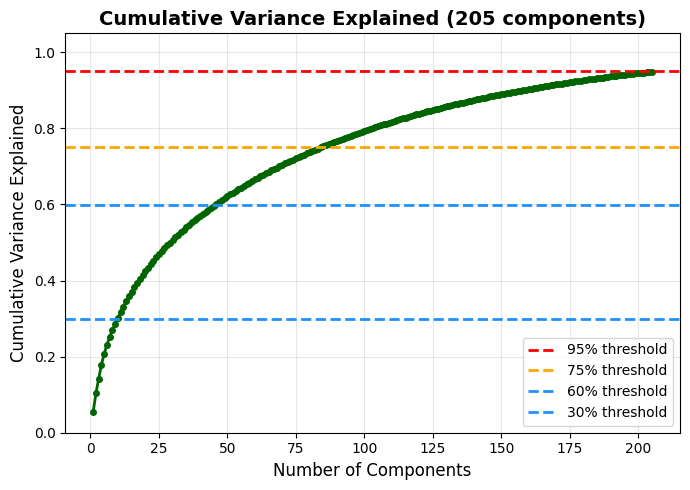


PCA ANALYSIS
Original embedding dimensions: 384

To preserve 75.0% of variance:
  → Need 85 components (reduced from 384)
  → Compression ratio: 22.14%

PCA Results:
  Number of components: 85
  Total variance explained: 0.7509 (75.09%)

  Top 10 components variance contribution:
    PC 1: 0.0556 ( 5.56%) | Cumulative: 0.0556 (5.56%)
    PC 2: 0.0483 ( 4.83%) | Cumulative: 0.1038 (10.38%)
    PC 3: 0.0386 ( 3.86%) | Cumulative: 0.1424 (14.24%)
    PC 4: 0.0360 ( 3.60%) | Cumulative: 0.1785 (17.85%)
    PC 5: 0.0293 ( 2.93%) | Cumulative: 0.2078 (20.78%)
    PC 6: 0.0227 ( 2.27%) | Cumulative: 0.2305 (23.05%)
    PC 7: 0.0214 ( 2.14%) | Cumulative: 0.2519 (25.19%)
    PC 8: 0.0177 ( 1.77%) | Cumulative: 0.2696 (26.96%)
    PC 9: 0.0164 ( 1.64%) | Cumulative: 0.2860 (28.60%)
    PC10: 0.0159 ( 1.59%) | Cumulative: 0.3019 (30.19%)


PCA ANALYSIS
Original embedding dimensions: 384

To preserve 30.0% of variance:
  → Need 10 components (reduced from 384)
  → Compression ratio: 2.60%

PCA R

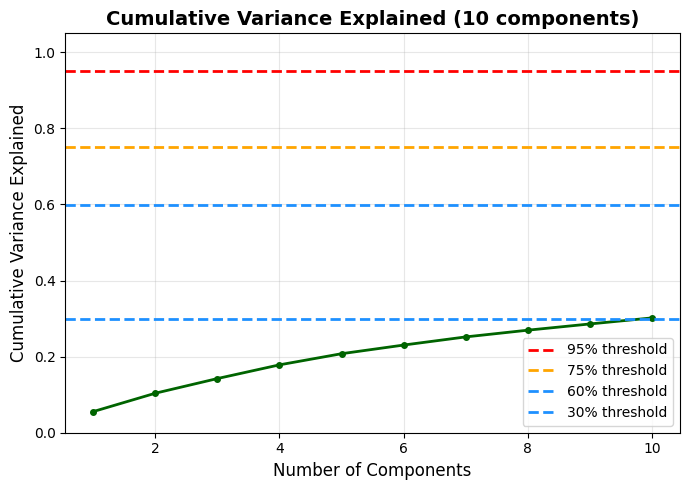

In [4]:
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')
print(f'SBERT max sequence length: {sbert_model.max_seq_length} word pieces')
profiles = users_sample['profile'].tolist()
user_ids = users_sample['user_id'].tolist()
embeddings = sbert_model.encode(profiles, convert_to_numpy=True, show_progress_bar=True)
token_counts = [len(sbert_model.tokenizer(p, add_special_tokens=True)['input_ids']) for p in profiles]
print(f'✓ Generated {len(embeddings)} embeddings of dimension {embeddings.shape[1]}; '
      f'{np.mean(np.array(token_counts) > sbert_model.max_seq_length):.0%} of profiles exceed the window and are truncated')

for threshold in [0.95, 0.75, 0.30]:
    _, _, explained = perform_pca_analysis(embeddings, n_components=None, variance_threshold=threshold)
    if threshold in (0.95, 0.30):
        plot_variance_explained(explained)


PCA ANALYSIS
Original embedding dimensions: 384

PCA Results:
  Number of components: 10
  Total variance explained: 0.3019 (30.19%)

  Top 10 components variance contribution:
    PC 1: 0.0556 ( 5.56%) | Cumulative: 0.0556 (5.56%)
    PC 2: 0.0483 ( 4.83%) | Cumulative: 0.1038 (10.38%)
    PC 3: 0.0386 ( 3.86%) | Cumulative: 0.1424 (14.24%)
    PC 4: 0.0360 ( 3.60%) | Cumulative: 0.1785 (17.85%)
    PC 5: 0.0293 ( 2.93%) | Cumulative: 0.2078 (20.78%)
    PC 6: 0.0227 ( 2.27%) | Cumulative: 0.2305 (23.05%)
    PC 7: 0.0214 ( 2.14%) | Cumulative: 0.2519 (25.19%)
    PC 8: 0.0177 ( 1.77%) | Cumulative: 0.2696 (26.96%)
    PC 9: 0.0164 ( 1.64%) | Cumulative: 0.2860 (28.60%)
    PC10: 0.0159 ( 1.59%) | Cumulative: 0.3019 (30.19%)

DISTANCE STATISTICS
Number of profile pairs: 499500
count    499500.000000
mean          0.999310
std           0.341472
min           0.003923
25%           0.776094
50%           1.030093
75%           1.248144
max           1.964828
Name: cosine_distance, dty

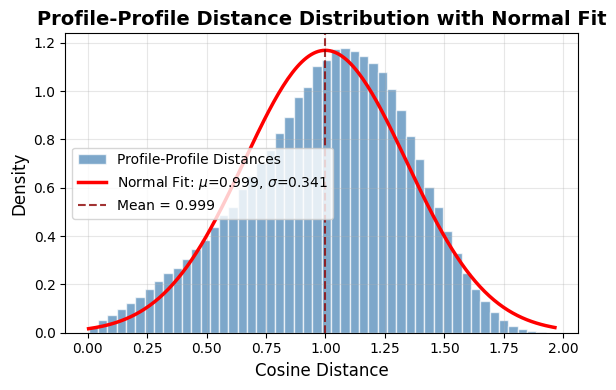


Normal fit: μ=0.9993, σ=0.3415
Shapiro-Wilk (n=5000): W=0.9893, p=5.3657e-19 → deviates from normal


In [5]:
pca_model, reduced_embeddings, explained_variance = perform_pca_analysis(embeddings, n_components=N_COMPONENTS)
distances = pairwise_cosine(reduced_embeddings)
result_df = pd.DataFrame({'user_id_1': np.array(user_ids)[np.triu_indices(len(user_ids), 1)[0]],
                          'user_id_2': np.array(user_ids)[np.triu_indices(len(user_ids), 1)[1]],
                          'cosine_distance': distances})
print(f"{'='*60}\nDISTANCE STATISTICS\n{'='*60}\nNumber of profile pairs: {len(result_df)}")
print(result_df['cosine_distance'].describe())

mu, std = stats.norm.fit(distances)
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(distances, bins=50, density=True, alpha=0.7, color='steelblue', edgecolor='white', label='Profile-Profile Distances')
x = np.linspace(distances.min(), distances.max(), 200)
ax.plot(x, stats.norm.pdf(x, mu, std), 'r-', linewidth=2.5, label=f'Normal Fit: $\\mu$={mu:.3f}, $\\sigma$={std:.3f}')
ax.axvline(mu, color='darkred', linestyle='--', linewidth=1.5, alpha=0.8, label=f'Mean = {mu:.3f}')
ax.set_xlabel('Cosine Distance', fontsize=12); ax.set_ylabel('Density', fontsize=12)
ax.set_title('Profile-Profile Distance Distribution with Normal Fit', fontsize=14, fontweight='bold')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout(); save_and_show(); plt.close()

np.random.seed(42)
sample = np.random.choice(distances, size=min(5000, len(distances)), replace=False)
stat, p_value = stats.shapiro(sample)
print(f'\nNormal fit: μ={mu:.4f}, σ={std:.4f}')
print(f'Shapiro-Wilk (n={len(sample)}): W={stat:.4f}, p={p_value:.4e} → '
      f"{'consistent with normal' if p_value > 0.05 else 'deviates from normal'}")

### 4b) Selected seven-parameter user representation

7 parameters:
  PC1 — comp1: μ=-0.2688, σ=0.1398 (w=0.268)
  PC1 — comp2: μ=0.0984, σ=0.1307 (w=0.732)
  PC2–10 avg : μ=0.0000, σ=0.1448


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Figure saved to: /Users/shaghosh/social-media-simulator/analyses/calibration/user/profile_post_representation/figures/social-media-archive-pc1-bimodal-gmm-fit.png


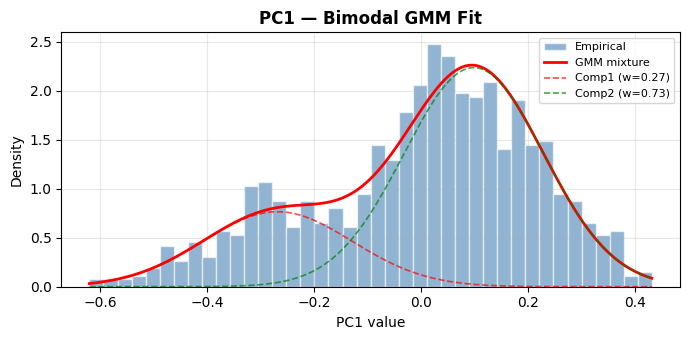

Figure saved to: /Users/shaghosh/social-media-simulator/analyses/calibration/user/profile_post_representation/figures/social-media-archive-random-distances-7-param-random-comparison-profile-vs-7-param-random.png


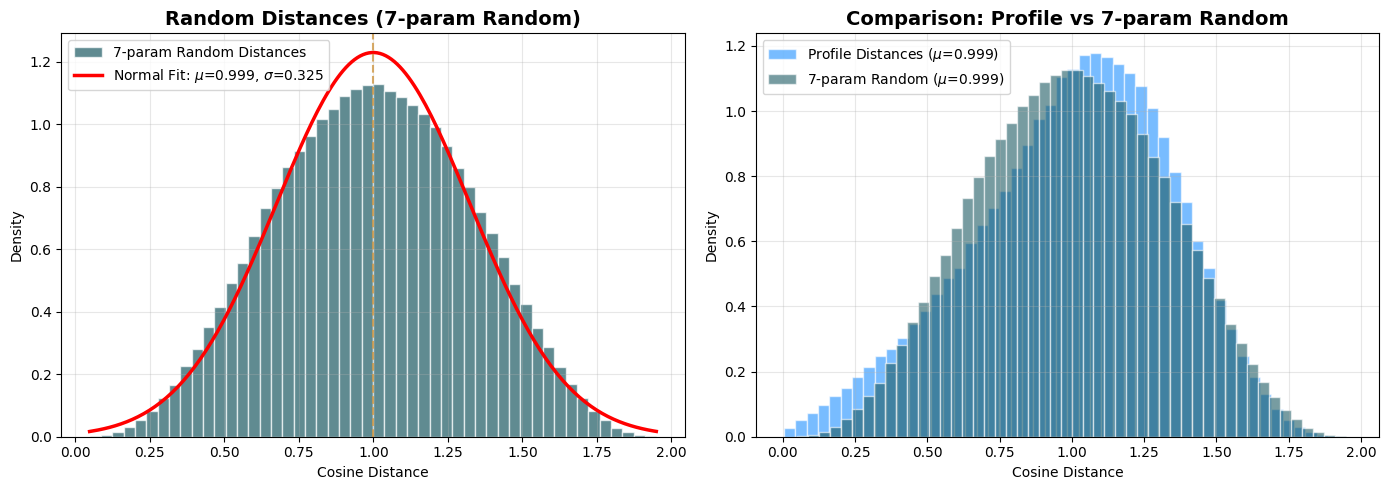


Metric                    Profile         7-param Random 
-------------------------------------------------------
Mean                      0.9993          0.9995         
Std Dev                   0.3415          0.3246         
Min                       0.0039          0.0478         
Max                       1.9648          1.9495         
Saved 7-parameter model to data/output/reports/pca_profile_7param_model_social_media_archive_profile.yaml


In [6]:
# 7 parameters: PC1 bimodal (5) + PC2–PC10 pooled (2).
gmm_pc1 = fit_gmm2(reduced_embeddings[:, 0])
m_rest, s_rest = pooled(1, 10)
print('7 parameters:\n' + describe_gmm('PC1', gmm_pc1) + f'\n  PC2–10 avg : μ={m_rest:.4f}, σ={s_rest:.4f}')

fig, axes = plt.subplots(1, 1, figsize=(7, 3.5))
for ax, (p, dim) in zip([axes], [(gmm_pc1, 0)]):
    v = reduced_embeddings[:, dim]
    xs = np.linspace(v.min(), v.max(), 300)
    ax.hist(v, bins=40, density=True, alpha=0.6, color='steelblue', edgecolor='white', label='Empirical')
    c1, c2 = p[2] * stats.norm.pdf(xs, p[0], p[1]), p[5] * stats.norm.pdf(xs, p[3], p[4])
    ax.plot(xs, c1 + c2, 'r-', linewidth=2, label='GMM mixture')
    ax.plot(xs, c1, 'r--', linewidth=1.2, alpha=0.7, label=f'Comp1 (w={p[2]:.2f})')
    ax.plot(xs, c2, 'g--', linewidth=1.2, alpha=0.7, label=f'Comp2 (w={p[5]:.2f})')
    ax.set_title(f'PC{dim+1} — Bimodal GMM Fit', fontsize=12, fontweight='bold')
    ax.set_xlabel(f'PC{dim+1} value'); ax.set_ylabel('Density'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); save_and_show(); plt.close()

np.random.seed(42)
v = np.zeros((N_RANDOM, N_COMPONENTS))
v[:, 0] = sample_bimodal(gmm_pc1, N_RANDOM)
v[:, 1:] = np.random.normal(m_rest, s_rest, size=(N_RANDOM, 9))
dists_7p = pairwise_cosine(v)
_ = compare_to_profiles(dists_7p, '7-param Random')

# Save the 7-parameter profile model for all downstream simulations.
import yaml

model_7p = {
    'model': {'name': 'pca_7param_social_media_archive_profile',
              'source_notebook': 'notebooks/2026-10-05-ODTW.ipynb',
              'embedding_model': 'all-MiniLM-L6-v2',
              'pca_variance_threshold': None, 'n_pca_dims': N_COMPONENTS,
              'pca_variance_explained': round(float(explained_variance.sum()), 6)},
    'parameters': {
        'pc1': {'distribution': 'gmm2',
                'component1': {'mu': round(float(gmm_pc1[0]), 6),
                               'sigma': round(float(gmm_pc1[1]), 6),
                               'weight': round(float(gmm_pc1[2]), 6)},
                'component2': {'mu': round(float(gmm_pc1[3]), 6),
                               'sigma': round(float(gmm_pc1[4]), 6),
                               'weight': round(float(gmm_pc1[5]), 6)}},
        'pc2_to_pc10': {'dims': list(range(2, 11)), 'distribution': 'gaussian_shared',
                        'mu': round(float(m_rest), 6), 'sigma': round(float(s_rest), 6)},
    },
}
yaml_path_7p = OUTPUT_DIR / 'pca_profile_7param_model_social_media_archive_profile.yaml'
with yaml_path_7p.open('w', encoding='utf-8') as stream:
    yaml.safe_dump(model_7p, stream, sort_keys=False)
print(f'Saved 7-parameter model to {yaml_path_7p.relative_to(PROJECT_ROOT)}')

### 4c) Initial post-count power law

Simulator setup uses a truncated discrete power law for initial post counts. The fit below estimates its exponent on the observed held-out post-count support.

In [7]:
from scipy.optimize import minimize_scalar

n_rest = users_sample['rest_posts'].apply(len).to_numpy()
PL_XMIN, PL_XMAX = int(n_rest.min()), int(n_rest.max())
support = np.arange(PL_XMIN, PL_XMAX + 1)
frequencies = np.bincount(n_rest, minlength=PL_XMAX + 1)[support]
def count_nll(alpha):
    probabilities = support.astype(float) ** -alpha
    probabilities /= probabilities.sum()
    return float(-frequencies @ np.log(probabilities))
POWER_LAW_ALPHA = float(minimize_scalar(count_nll, bounds=(1.001, 10.0), method='bounded').x)
power_law_config = {'alpha': POWER_LAW_ALPHA, 'x_min': PL_XMIN, 'x_max': PL_XMAX}
display(pd.DataFrame([power_law_config]))
with (OUTPUT_DIR / 'rest_post_count_power_law.yaml').open('w') as stream:
    yaml.safe_dump({'power_law': power_law_config}, stream)

,alpha,x_min,x_max
0,3.066159,10,49


### 4d) Empirical held-out post representation and generalized-gamma distance fit

In [8]:
import math
import yaml
from scipy.spatial.distance import cosine, pdist
from scipy.stats import wasserstein_distance
from sklearn.mixture import GaussianMixture

YAML_PATH = yaml_path_7p
RANDOM_STATE = 42
N_SIM = 1000
MAX_POOLED_POSTS = 3000   # posts sampled for pooled post–post distances (see the note above)

users_rp = users_sample.reset_index(drop=True)   # positional index, as in the original notebook
first_half_ok = all(
    row.profile == row.user_description + ' ' + ' '.join(s for s in row.posts_list[:math.ceil(len(row.posts_list) / 2)] if pd.notnull(s))
    and row.rest_posts == row.posts_list[math.ceil(len(row.posts_list) / 2):]
    for row in users_rp.itertuples())
print('Checked: every profile = description + first 50% of posts; rest_posts = remaining posts.')

profile_emb_raw = embeddings            # SBERT profile embeddings from section 3 (same order)
profile_emb_pca = reduced_embeddings    # 10-component profile PCA from section 4
n_dims = profile_emb_pca.shape[1]

user_pos_list, post_text_list = [], []
for pos, row in users_rp.iterrows():
    for post in row['rest_posts']:
        if post and pd.notnull(post):
            user_pos_list.append(pos)
            post_text_list.append(str(post).strip())

post_emb_raw = sbert_model.encode(post_text_list, convert_to_numpy=True, show_progress_bar=True, batch_size=128)
post_emb_pca = pca_model.transform(post_emb_raw)
print(f'Profile embeddings: {profile_emb_raw.shape}; rest_post embeddings: {post_emb_raw.shape} ({len(post_text_list):,} posts)')
print(f'Profiles and rest_posts share the {n_dims}-D profile PCA space '
      f'({pca_model.explained_variance_ratio_.sum():.2%} of profile variance).')

Checked: every profile = description + first 50% of posts; rest_posts = remaining posts.


Batches:   0%|          | 0/124 [00:00<?, ?it/s]

Profile embeddings: (1000, 384); rest_post embeddings: (15804, 384) (15,804 posts)
Profiles and rest_posts share the 10-D profile PCA space (30.19% of profile variance).


Users with rest_posts: 1000
Total profile–post pairs: 15,804
All-pairs: μ=0.4220, σ=0.3250
Per-user mean distance: μ=0.4358, σ=0.2479
n_rest_posts: median=13, mean=15.8, max=49
Figure saved to: /Users/shaghosh/social-media-simulator/analyses/calibration/user/profile_post_representation/figures/social-media-archive-empirical-profile-post-distances-all-pairs-per-user-mean-profile-post-distance.png


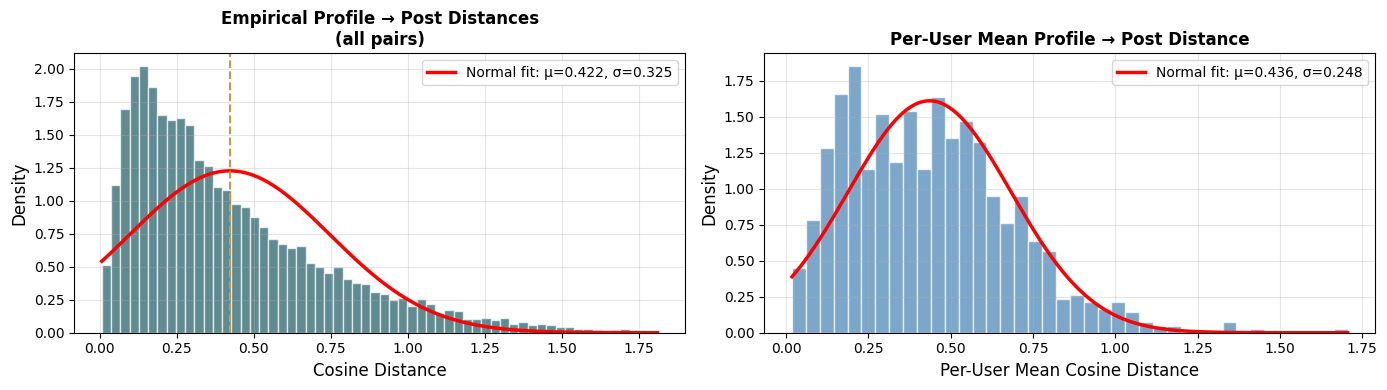

In [9]:
posts_by_user = {i: [] for i in range(len(users_rp))}
for flat_idx, pos in enumerate(user_pos_list):
    posts_by_user[pos].append(post_emb_pca[flat_idx])

empirical_records = []
for pos, row in users_rp.iterrows():
    pvec, pvecs = profile_emb_pca[pos], posts_by_user[pos]
    if not pvecs:
        continue
    dists = [cosine(pvec, pv) for pv in pvecs]
    empirical_records.append({'user_id': row['user_id'], 'n_posts': len(dists), 'mean_dist': float(np.mean(dists)),
                              'std_dist': float(np.std(dists)), 'all_dists': dists})

empirical_df = pd.DataFrame(empirical_records)
all_empirical_dists = np.concatenate(empirical_df['all_dists'].values)
mu_ep, std_ep = stats.norm.fit(all_empirical_dists)
emp_means = empirical_df['mean_dist'].values

print(f'Users with rest_posts: {len(empirical_df)}')
print(f'Total profile–post pairs: {len(all_empirical_dists):,}')
print(f'All-pairs: μ={mu_ep:.4f}, σ={std_ep:.4f}')
print(f'Per-user mean distance: μ={emp_means.mean():.4f}, σ={emp_means.std(ddof=1):.4f}')
print(f'n_rest_posts: median={empirical_df["n_posts"].median():.0f}, mean={empirical_df["n_posts"].mean():.1f}, '
      f'max={empirical_df["n_posts"].max()}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(all_empirical_dists, bins=60, density=True, alpha=0.7, color='#1C5A62', edgecolor='white')
x = np.linspace(all_empirical_dists.min(), all_empirical_dists.max(), 300)
axes[0].plot(x, stats.norm.pdf(x, mu_ep, std_ep), 'r-', linewidth=2.5, label=f'Normal fit: μ={mu_ep:.3f}, σ={std_ep:.3f}')
axes[0].axvline(mu_ep, color='#ce9642', linestyle='--', linewidth=1.5)
axes[0].set_title('Empirical Profile → Post Distances\n(all pairs)', fontsize=12, fontweight='bold')
mu_m, std_m = stats.norm.fit(emp_means)
axes[1].hist(emp_means, bins=40, density=True, alpha=0.7, color='steelblue', edgecolor='white')
x2 = np.linspace(emp_means.min(), emp_means.max(), 200)
axes[1].plot(x2, stats.norm.pdf(x2, mu_m, std_m), 'r-', linewidth=2.5, label=f'Normal fit: μ={mu_m:.3f}, σ={std_m:.3f}')
axes[1].set_title('Per-User Mean Profile → Post Distance', fontsize=12, fontweight='bold')
for ax, xl in zip(axes, ['Cosine Distance', 'Per-User Mean Cosine Distance']):
    ax.set_xlabel(xl, fontsize=12); ax.set_ylabel('Density', fontsize=12); ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout(); save_and_show(); plt.close()

,a,c,loc,scale,KS,KS p-value
0,0.585929,1.895015,0.00636,0.692624,0.059721,1.933496e-49


Figure saved to: /Users/shaghosh/social-media-simulator/analyses/calibration/user/profile_post_representation/figures/social-media-archive-profile-post-distance-calibration.png


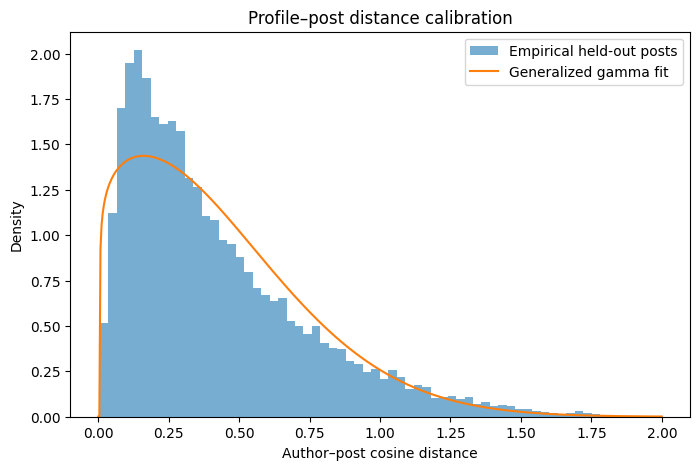

In [10]:
gg_params = stats.gengamma.fit(all_empirical_dists)
ks_stat, ks_p = stats.kstest(all_empirical_dists, stats.gengamma.cdf, args=gg_params)
gen_gamma_config = dict(zip(['a', 'c', 'loc', 'scale'], map(float, gg_params)))
display(pd.DataFrame([{**gen_gamma_config, 'KS': ks_stat, 'KS p-value': ks_p}]))
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(all_empirical_dists, bins=60, density=True, alpha=.6, label='Empirical held-out posts')
x = np.linspace(0, 2, 500)
ax.plot(x, stats.gengamma.pdf(x, *gg_params), label='Generalized gamma fit')
ax.set(xlabel='Author–post cosine distance', ylabel='Density', title='Profile–post distance calibration')
ax.legend(); save_and_show(); plt.close()

### 4e) Generate profiles and posts with the selected simulator models

Generalized-gamma draws outside [0, 2] are rejected, matching the simulator.

In [11]:
from scipy.special import zeta
from scipy.stats import gengamma

SIM_YAML_PATH = yaml_path_7p
N_USERS = 1_000
SEED = 20261004
# power_law_config is fitted above
POWER_LAW_ALPHA = float(power_law_config['alpha'])
PL_XMIN, PL_XMAX = int(power_law_config['x_min']), int(power_law_config['x_max'])
GENGAMMA_PARAMS = tuple(float(v) for v in gg_params)               # section 10.3 (a, c, loc, scale)
rng = np.random.default_rng(SEED)

print(f'YAML: {SIM_YAML_PATH.relative_to(PROJECT_ROOT)}')
print(f'Users: {N_USERS:,}; power-law α = {POWER_LAW_ALPHA:.4f} on k ∈ [{PL_XMIN}, {PL_XMAX}]')
print(f'Gen. gamma (a, c, loc, scale) = {tuple(round(v, 6) for v in GENGAMMA_PARAMS)}')
print(f'For reference, an unbounded zipf with this α gives P(K ≥ 10) = {zeta(POWER_LAW_ALPHA, 10) / zeta(POWER_LAW_ALPHA, 1):.3%}')

with SIM_YAML_PATH.open('r', encoding='utf-8') as stream:
    profile_config = yaml.safe_load(stream)
model = profile_config['model']
spec = profile_config['parameters']

def sample_gmm2(gmm_spec, size, rng):
    c1, c2 = gmm_spec['component1'], gmm_spec['component2']
    weights = np.array([c1['weight'], c2['weight']], dtype=float)
    weights /= weights.sum()
    component = rng.choice(2, size=size, p=weights)
    means = np.array([c1['mu'], c2['mu']], dtype=float)
    sigmas = np.array([c1['sigma'], c2['sigma']], dtype=float)
    return rng.normal(means[component], sigmas[component])

user_profiles = np.empty((N_USERS, model['n_pca_dims']), dtype=float)
user_profiles[:, 0] = sample_gmm2(spec['pc1'], N_USERS, rng)
shared = spec['pc2_to_pc10']
shared_dims = np.asarray(shared['dims']) - 1
user_profiles[:, shared_dims] = rng.normal(loc=shared['mu'], scale=shared['sigma'], size=(N_USERS, len(shared_dims)))

profile_columns = [f'pc{i}' for i in range(1, 11)]
users_df = pd.DataFrame(user_profiles, columns=profile_columns)
users_df.insert(0, 'user_id', np.arange(N_USERS))
print(f"Loaded model '{model['name']}' and generated {len(users_df):,} user profiles.")
display(users_df[profile_columns].describe().round(4))

YAML: data/output/reports/pca_profile_7param_model_social_media_archive_profile.yaml
Users: 1,000; power-law α = 3.0662 on k ∈ [10, 49]
Gen. gamma (a, c, loc, scale) = (0.585929, 1.895015, 0.00636, 0.692624)
For reference, an unbounded zipf with this α gives P(K ≥ 10) = 0.387%
Loaded model 'pca_7param_social_media_archive_profile' and generated 1,000 user profiles.


,pc1,pc2,pc3,pc4,pc5,pc6,pc7,pc8,pc9,pc10
count,1000.0000,1000.0000,1000.0000,1000.0000,1000.0000,1000.0000,1000.0000,1000.0000,1000.0000,1000.0000
mean,-0.0081,0.0019,0.0001,0.0085,0.0087,-0.0102,-0.0067,-0.0078,-0.0043,-0.0015
std,0.2133,0.1431,0.1450,0.1411,0.1436,0.1447,0.1468,0.1415,0.1481,0.1431
min,-0.7179,-0.4833,-0.3910,-0.4112,-0.4481,-0.5458,-0.4330,-0.4561,-0.4389,-0.4513
25%,-0.1582,-0.0909,-0.0974,-0.0865,-0.0891,-0.0985,-0.1100,-0.1034,-0.1072,-0.0993
50%,0.0322,0.0048,-0.0040,0.0064,0.0141,-0.0093,-0.0067,-0.0114,-0.0071,-0.0023
75%,0.1481,0.0958,0.1045,0.0989,0.1006,0.0849,0.0965,0.0856,0.0960,0.0997
max,0.5302,0.4395,0.3858,0.4710,0.4767,0.5129,0.3830,0.4504,0.4399,0.4718


Total posts: 15,919


,n_posts
count,1000.00
mean,15.92
std,7.42
min,10.00
50%,13.00
90%,27.00
95%,32.00
99%,43.01
max,49.00


Figure saved to: /Users/shaghosh/social-media-simulator/analyses/calibration/user/profile_post_representation/figures/social-media-archive-simulated-post-counts-archive-calibrated-power-law-simulated-post-count-ccdf.png


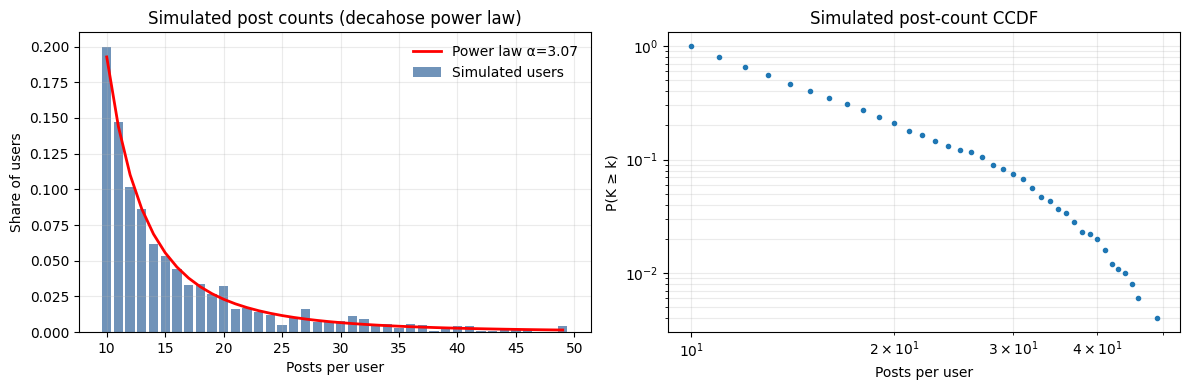

In [12]:
support = np.arange(PL_XMIN, PL_XMAX + 1)
support_probs = support.astype(float) ** -POWER_LAW_ALPHA
support_probs /= support_probs.sum()
post_counts = rng.choice(support, size=N_USERS, p=support_probs)
post_counts_df = pd.DataFrame({'user_id': np.arange(N_USERS), 'n_posts': post_counts})
print(f'Total posts: {post_counts.sum():,}')
display(post_counts_df['n_posts'].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame().round(2))

counts, frequencies = np.unique(post_counts, return_counts=True)
ccdf = np.array([(post_counts >= value).mean() for value in counts])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(counts, frequencies / N_USERS, color='#4C78A8', alpha=.8, label='Simulated users')
axes[0].plot(support, support_probs, 'r-', lw=2, label=f'Power law α={POWER_LAW_ALPHA:.2f}')
axes[0].set(xlabel='Posts per user', ylabel='Share of users', title='Simulated post counts (archive-calibrated power law)')
axes[0].legend(frameon=False)
axes[1].loglog(counts, ccdf, marker='.', linestyle='none')
axes[1].set(xlabel='Posts per user', ylabel='P(K ≥ k)', title='Simulated post-count CCDF')
for ax in axes: ax.grid(alpha=.25, which='both')
plt.tight_layout(); save_and_show(); plt.close()

In [13]:
def generate_post_at_angle(u: np.ndarray, alpha: float, rng=None) -> np.ndarray:
    # Generate p at angle alpha (radians) from u, with |p| = |u|.
    if rng is None:
        rng = np.random.default_rng()
    norm_u = np.linalg.norm(u)
    if norm_u == 0:
        return u.copy()
    alpha = float(np.clip(alpha, 0.0, np.pi))
    u_hat = u / norm_u
    v = rng.standard_normal(u.shape)
    v -= np.dot(v, u_hat) * u_hat
    while np.linalg.norm(v) <= 1e-12:
        v = rng.standard_normal(u.shape)
        v -= np.dot(v, u_hat) * u_hat
    v /= np.linalg.norm(v)
    # cos(u, p) = cos(alpha), so cosine_distance(u, p) = 1 - cos(alpha).
    return norm_u * (np.cos(alpha) * u_hat + np.sin(alpha) * v)

Generated 15,919 posts for 1,000 users.
Maximum target-versus-realized distance error: 8.882e-16; norm error: 3.331e-16


,value
users,1000.0000
posts,15919.0000
mean posts/user,15.9190
median posts/user,13.0000
mean cosine distance,0.4413
median cosine distance,0.3795
empirical mean profile→post distance (10.2),0.4220


Figure saved to: /Users/shaghosh/social-media-simulator/analyses/calibration/user/profile_post_representation/figures/social-media-archive-generated-post-distances-vs-empirical-distance-preservation.png


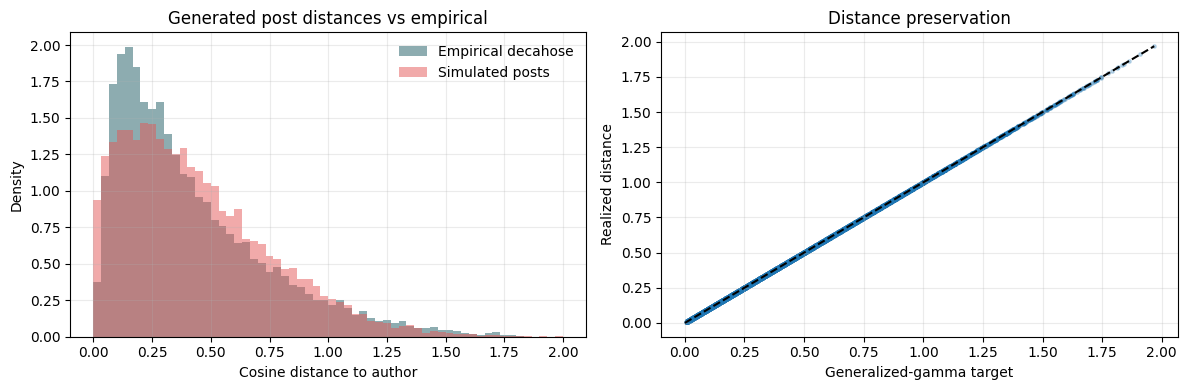

In [14]:
from scipy.stats import gengamma

def sample_valid_cosine_distances(size, rng):
    a, c, loc, scale = GENGAMMA_PARAMS
    result = np.empty(size, dtype=float)
    filled = 0
    while filled < size:
        draw_size = max(1_024, 2 * (size - filled))
        candidates_ = gengamma.rvs(a=a, c=c, loc=loc, scale=scale, size=draw_size, random_state=rng)
        accepted = candidates_[(candidates_ >= 0.0) & (candidates_ <= 2.0)]
        take = min(len(accepted), size - filled)
        if take:
            result[filled:filled + take] = accepted[:take]
            filled += take
    return result

author_ids = np.repeat(np.arange(N_USERS), post_counts)
author_vectors = user_profiles[author_ids]
author_norms = np.linalg.norm(author_vectors, axis=1)
n_posts_total = len(author_ids)

target_distances = sample_valid_cosine_distances(n_posts_total, rng)
alphas = np.arccos(np.clip(1.0 - target_distances, -1.0, 1.0))
post_vectors = np.asarray([generate_post_at_angle(user_profiles[author_id], alpha, rng)
                           for author_id, alpha in zip(author_ids, alphas)])

post_norms_all = np.linalg.norm(post_vectors, axis=1)
realized_distances = 1.0 - np.sum(author_vectors * post_vectors, axis=1) / (author_norms * post_norms_all)
within_user_post_id = np.concatenate([np.arange(count) for count in post_counts])
posts_df = pd.DataFrame(post_vectors, columns=profile_columns)
posts_df.insert(0, 'cosine_distance_to_author', realized_distances)
posts_df.insert(0, 'post_id_within_user', within_user_post_id)
posts_df.insert(0, 'user_id', author_ids)

max_distance_error = np.max(np.abs(realized_distances - target_distances))
max_norm_error = np.max(np.abs(post_norms_all - author_norms))
print(f'Generated {len(posts_df):,} posts for {N_USERS:,} users.')
print(f'Maximum target-versus-realized distance error: {max_distance_error:.3e}; norm error: {max_norm_error:.3e}')
display(pd.Series({'users': N_USERS, 'posts': n_posts_total, 'mean posts/user': post_counts.mean(),
                   'median posts/user': np.median(post_counts), 'mean cosine distance': realized_distances.mean(),
                   'median cosine distance': np.median(realized_distances),
                   'empirical mean profile→post distance (10.2)': all_empirical_dists.mean()},
                  name='value').to_frame().round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, 2, 61)
axes[0].hist(all_empirical_dists, bins=bins, density=True, alpha=.5, color='#1C5A62', label='Empirical archive sample')
axes[0].hist(realized_distances, bins=bins, density=True, alpha=.5, color='#E45756', label='Simulated posts')
axes[0].set(xlabel='Cosine distance to author', ylabel='Density', title='Generated post distances vs empirical')
axes[0].legend(frameon=False)
axes[1].scatter(target_distances, realized_distances, s=6, alpha=0.25)
limits = [0.0, max(target_distances.max(), realized_distances.max())]
axes[1].plot(limits, limits, '--', color='black')
axes[1].set(xlabel='Generalized-gamma target', ylabel='Realized distance', title='Distance preservation')
for ax in axes: ax.grid(alpha=.25)
plt.tight_layout(); save_and_show(); plt.close()

## 5) Conclusion and default calibration values

The earlier implementation uses ten profile dimensions (30.1883% explained variance in the source run), a seven-parameter profile model, a truncated post-count power law, and generalized-gamma profile–post distances.

Recorded simulator defaults from that run:
- **PC1 component 1**: mean −0.268814, SD 0.139779, weight 0.267976.
- **PC1 component 2**: mean 0.098406, SD 0.130654, weight 0.732024.
- **PC2–PC10**: shared mean 0.0, SD 0.144802.
- **Post counts**: exponent 3.066159, support 10–49.
- **Generalized gamma**: a=0.559463, c=1.943292, loc=0.006263, scale=0.711543.

These are recorded defaults, not newly executed results. The final cell exports recomputed parameters in the simulator's configuration shape; review differences before updating defaults. Small numerical differences can follow from dependency versions and fitting algorithms. The single-day, high-activity, English-description sample limits generalization to other user populations.

In [15]:
calibration = {
    'vector_profile_generation_function': {
        'pca_7param_social_media_archive_profile': {
            'dimension': N_COMPONENTS,
            'pc1': {k: v for k, v in model_7p['parameters']['pc1'].items() if k != 'distribution'},
            'pc2_to_pc10': {k: model_7p['parameters']['pc2_to_pc10'][k] for k in ['mu', 'sigma']},
        }
    },
    'content_embedding_generation_function': {
        'social_media_archive_content_embedding': {'power_law': power_law_config, 'gen_gamma': gen_gamma_config}
    },
}
with (OUTPUT_DIR / 'profile_post_representation_calibration.yaml').open('w') as stream:
    yaml.safe_dump({'user_behavior': calibration}, stream, sort_keys=False)
display(calibration)

{'vector_profile_generation_function': {'pca_7param_social_media_archive_profile': {'dimension': 10,
   'pc1': {'component1': {'mu': -0.268814,
     'sigma': 0.139779,
     'weight': 0.267976},
    'component2': {'mu': 0.098406, 'sigma': 0.130654, 'weight': 0.732024}},
   'pc2_to_pc10': {'mu': 0.0, 'sigma': 0.144804}}},
 'content_embedding_generation_function': {'social_media_archive_content_embedding': {'power_law': {'alpha': 3.066158612083357,
    'x_min': 10,
    'x_max': 49},
   'gen_gamma': {'a': 0.5859286736560252,
    'c': 1.8950147222225866,
    'loc': 0.006359853663361964,
    'scale': 0.6926240750422168}}}}